In [1]:
import os
import random
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from tqdm import tqdm

# Scikit-learn imports
from sklearn.impute import SimpleImputer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, VotingClassifier

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [2]:
base_path = "/kaggle/input/noise-reduced-uaspeech-dysarthria-dataset"

In [3]:
def load_audio_files(base_path):
    audio_files = []
    labels = []
    
    # Define dataset subdirectories
    subdirs = ['noisereduced-uaspeech', 'noisereduced-uaspeech-control']
    
    for subdir in tqdm(subdirs, desc="Processing Directories"):
        current_path = os.path.join(base_path, subdir)
        
        # Determine label based on directory
        label = 'Control' if 'control' in subdir else 'Dysarthric'
        
        # Walk through all audio files
        for root, dirs, files in os.walk(current_path):
            for file in tqdm(files, desc=f"Scanning {subdir}", leave=False):
                if file.endswith('.wav'):
                    file_path = os.path.join(root, file)
                    audio_files.append(file_path)
                    labels.append(label)
    
    return audio_files, labels

In [4]:
def sample_audio_files(audio_files, labels, total_samples=4000):
    """
    Randomly sample files while maintaining class balance
    """
    df = pd.DataFrame({
        'file_path': audio_files,
        'label': labels
    })
    
    sampled_df = df.groupby('label', group_keys=False).apply(
        lambda x: x.sample(n=total_samples//2)
    )
    
    return list(sampled_df['file_path']), list(sampled_df['label'])

In [5]:
class AlexNetFeatureExtractor(nn.Module):
    def __init__(self, n_mels=128, duration=3):
        super().__init__()
        self.n_mels = n_mels
        self.duration = duration
        
        # Load pre-trained AlexNet
        self.alexnet = torch.hub.load('pytorch/vision:v0.10.0', 'alexnet', pretrained=True)
        
        # Remove the classifier layers to use as a feature extractor
        self.features = nn.Sequential(*list(self.alexnet.features.children()))
        
    def extract_mel_spectrogram(self, file_path):
        """
        Generate Mel-Spectrogram from audio file
        """
        try:
            # Load audio
            y, sr = librosa.load(file_path, duration=self.duration)
            
            # Generate Mel-Spectrogram
            mel_spec = librosa.feature.melspectrogram(
                y=y, sr=sr, n_mels=self.n_mels
            )
            
            # Convert to log scale (dB)
            mel_spec_db = librosa.power_to_db(mel_spec, ref=np.max)
            
            # Normalize
            mel_spec_norm = (mel_spec_db - mel_spec_db.min()) / (mel_spec_db.max() - mel_spec_db.min())
            
            return mel_spec_norm
        except Exception as e:
            print(f"Error processing {file_path}: {e}")
            return None


In [6]:
def prepare_feature_vectors(audio_files, labels):
    """
    Prepare feature vectors using AlexNet feature extraction
    """
    # Feature Extractor
    feature_extractor = AlexNetFeatureExtractor()
    
    # Prepare feature matrices
    features = []
    dataset_labels = []
    
    # Label Encoder
    le = LabelEncoder()
    encoded_labels = le.fit_transform(labels)
    
    # Extract features with progress bar
    for file_path, label in tqdm(zip(audio_files, encoded_labels), 
                                  total=len(audio_files), 
                                  desc="Extracting Features"):
        # Extract Mel-Spectrogram
        mel_spec = feature_extractor.extract_mel_spectrogram(file_path)
        
        if mel_spec is not None:
            # Ensure consistent feature size (128x128)
            mel_spec_resized = mel_spec[:128, :128]
            mel_spec_resized = np.pad(
                mel_spec_resized, 
                ((0, 128 - mel_spec_resized.shape[0]), (0, 128 - mel_spec_resized.shape[1])), 
                mode='constant'
            )
            
            # Convert to torch tensor and add batch and channel dimensions
            mel_tensor = torch.from_numpy(mel_spec_resized).float().unsqueeze(0).repeat(3, 1, 1).unsqueeze(0)
            
            # Extract features using AlexNet
            with torch.no_grad():
                feature_vec = feature_extractor.features(mel_tensor).view(-1).numpy()
            
            features.append(feature_vec)
            dataset_labels.append(label)
    
    # Convert to numpy arrays
    X = np.array(features)
    y = np.array(dataset_labels)
    
    return X, y

In [7]:
def train_multiple_classifiers(X, y, test_size=0.2, random_state=42):
    """
    Train multiple classifiers: KNN, SVM, Random Forest, and an ensemble
    """
    # Handle missing values using an imputer
    imputer = SimpleImputer(strategy='mean')
    X = imputer.fit_transform(X)
    
    # Scale features
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(
        X_scaled, y, 
        test_size=test_size, 
        random_state=random_state,
        stratify=y  # Ensure balanced class distribution
    )
    
    # Define classifiers
    classifiers = {
        'KNN': KNeighborsClassifier(n_neighbors=5),
        'SVM': SVC(kernel='rbf', probability=True, random_state=random_state),
        'Random Forest': RandomForestClassifier(
            n_estimators=100, 
            random_state=random_state
        ),
        'XGBoost': XGBClassifier(
            n_estimators=100, 
            learning_rate=0.1, 
            random_state=random_state
        ),
        'CatBoost': CatBoostClassifier(
            iterations=100, 
            learning_rate=0.1, 
            random_state=random_state,
            verbose=0
        )
    }
    
    # Results dictionary
    results = {}
    
    # Train and evaluate each classifier
    for name, clf in tqdm(classifiers.items(), desc="Training Classifiers"):
        clf.fit(X_train, y_train)
        y_pred = clf.predict(X_test)
        
        # Generate classification report
        class_names = ['Control', 'Dysarthric']
        results[name] = {
            'classification_report': classification_report(
                y_test, y_pred, 
                target_names=class_names
            ),
            'confusion_matrix': confusion_matrix(y_test, y_pred)
        }
    
    # Ensemble Voting Classifier
    ensemble_clf = VotingClassifier(
        estimators=[(name, clf) for name, clf in classifiers.items()],
        voting='soft'
    )
    
    # Train ensemble
    ensemble_clf.fit(X_train, y_train)
    y_pred_ensemble = ensemble_clf.predict(X_test)
    
    # Ensemble results
    results['Ensemble'] = {
        'classification_report': classification_report(
            y_test, y_pred_ensemble, 
            target_names=['Control', 'Dysarthric']
        ),
        'confusion_matrix': confusion_matrix(y_test, y_pred_ensemble)
    }
    
    return results

In [8]:
def plot_confusion_matrix(conf_matrix, class_names, title):
    """
    Plot confusion matrix
    """
    plt.figure(figsize=(8, 6))
    sns.heatmap(
        conf_matrix, 
        annot=True, 
        fmt='d', 
        xticklabels=class_names, 
        yticklabels=class_names,
        cmap='Blues'
    )
    plt.title(title)
    plt.xlabel('Predicted Label')
    plt.ylabel('True Label')
    plt.tight_layout()
    plt.show()


In [9]:
    print("Step 1: Loading All Audio Files")
    audio_files, labels = load_audio_files(base_path)
    print(f"Total audio files found: {len(audio_files)}")

Step 1: Loading All Audio Files


Scanning noisereduced-uaspeech:   0%|          | 0/2 [00:00<?, ?it/s]
                                                                     
Scanning noisereduced-uaspeech:   0%|          | 0/4590 [00:00<?, ?it/s]
                                                                        
Scanning noisereduced-uaspeech:   0%|          | 0/5355 [00:00<?, ?it/s]
                                                                        
Scanning noisereduced-uaspeech:   0%|          | 0/4590 [00:00<?, ?it/s]
                                                                        
Scanning noisereduced-uaspeech:   0%|          | 0/5355 [00:00<?, ?it/s]
                                                                        
Scanning noisereduced-uaspeech:   0%|          | 0/3825 [00:00<?, ?it/s]
                                                                        
Scanning noisereduced-uaspeech:   0%|          | 0/4590 [00:00<?, ?it/s]
                                                         

Total audio files found: 143290


In [10]:
    print("\nStep 2: Sampling 4000 Files")
    sampled_audio_files, sampled_labels = sample_audio_files(
        audio_files, labels, total_samples=4000
    )
    print(f"Sampled audio files: {len(sampled_audio_files)}")
    print(f"Control samples: {sampled_labels.count('Control')}")
    print(f"Dysarthric samples: {sampled_labels.count('Dysarthric')}")


Step 2: Sampling 4000 Files
Sampled audio files: 4000
Control samples: 2000
Dysarthric samples: 2000


/tmp/ipykernel_23/3394421251.py:10: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  sampled_df = df.groupby('label', group_keys=False).apply(


In [11]:
    print("\nPreparing Feature Vectors with AlexNet")
    X, y = prepare_feature_vectors(sampled_audio_files, sampled_labels)
    print(f"Feature matrix shape: {X.shape}")
    print(f"Labels shape: {y.shape}")


Preparing Feature Vectors with AlexNet


Downloading: "https://github.com/pytorch/vision/zipball/v0.10.0" to /root/.cache/torch/hub/v0.10.0.zip
Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth
100%|██████████| 233M/233M [00:03<00:00, 81.1MB/s] 
Extracting Features: 100%|██████████| 4000/4000 [03:12<00:00, 20.73it/s]


Feature matrix shape: (4000, 2304)
Labels shape: (4000,)


In [13]:
import pandas as pd
import numpy as np
from IPython.display import FileLink

# Ensure y is a NumPy array and reshape it to match X's dimensions
y = np.array(y).reshape(-1, 1)  # Convert to 2D column vector

# Convert to DataFrame
data = np.hstack((X, y))  # Combine features and labels
columns = [f'Feature_{i+1}' for i in range(X.shape[1])] + ['Label']
df = pd.DataFrame(data, columns=columns)

# Save as CSV
csv_filename = "extracted_audio_features.csv"
df.to_csv(csv_filename, index=False)

# Generate and display the download link
FileLink(csv_filename)


/kaggle/working/extracted_audio_features.csv

In [14]:
# Gradient Boosting imports
from xgboost import XGBClassifier
from catboost import CatBoostClassifier

In [15]:
    print("\nTraining Multiple Classifiers")
    results = train_multiple_classifiers(X, y)


Training Multiple Classifiers


Training Classifiers:   0%|          | 0/5 [00:00<?, ?it/s]/opt/conda/lib/python3.10/site-packages/sklearn/neighbors/_classification.py:215: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return self._fit(X, y)
Training Classifiers:  20%|██        | 1/5 [00:00<00:00,  4.14it/s]/opt/conda/lib/python3.10/site-packages/sklearn/utils/validation.py:1143: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)
Training Classifiers:  40%|████      | 2/5 [00:29<00:52, 17.51s/it]/tmp/ipykernel_23/1557068380.py:47: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  clf.fit(X_train, y_train)
Training Classifiers: 100%|██████████| 5/5 [01:03<00:00, 12.61s


KNN Classifier Results:
              precision    recall  f1-score   support

     Control       0.91      0.93      0.92       400
  Dysarthric       0.92      0.91      0.92       400

    accuracy                           0.92       800
   macro avg       0.92      0.92      0.92       800
weighted avg       0.92      0.92      0.92       800



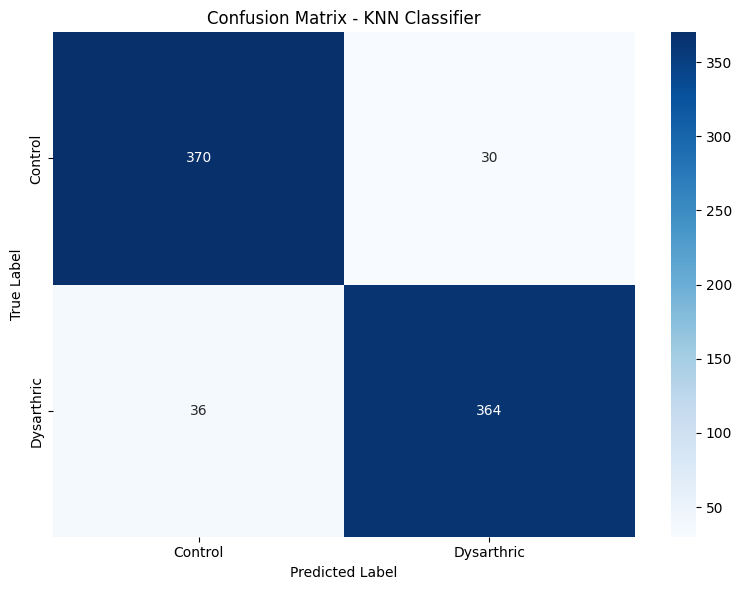


SVM Classifier Results:
              precision    recall  f1-score   support

     Control       0.94      0.93      0.94       400
  Dysarthric       0.93      0.94      0.94       400

    accuracy                           0.94       800
   macro avg       0.94      0.94      0.94       800
weighted avg       0.94      0.94      0.94       800



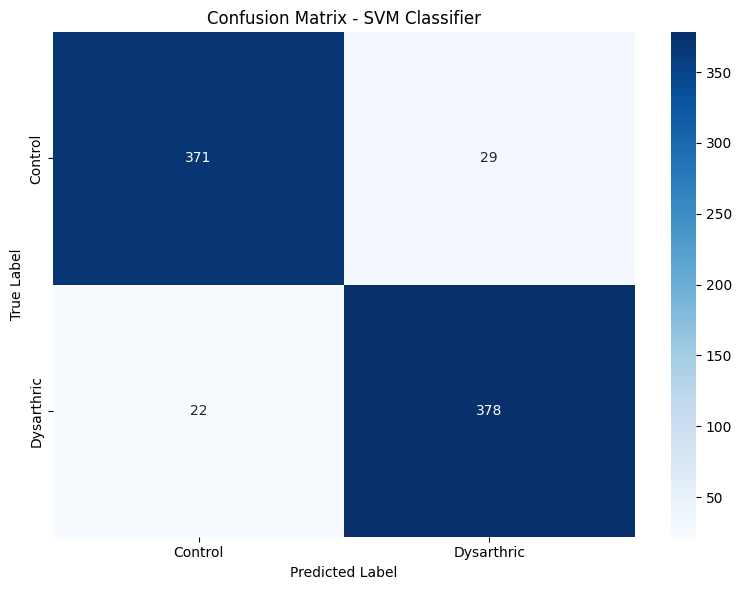


Random Forest Classifier Results:
              precision    recall  f1-score   support

     Control       0.92      0.93      0.92       400
  Dysarthric       0.93      0.92      0.92       400

    accuracy                           0.92       800
   macro avg       0.92      0.92      0.92       800
weighted avg       0.92      0.92      0.92       800



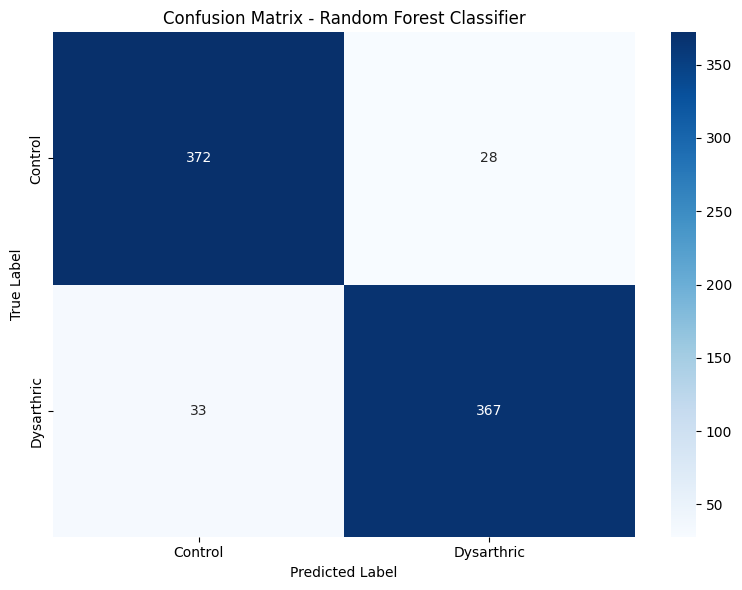


XGBoost Classifier Results:
              precision    recall  f1-score   support

     Control       0.94      0.94      0.94       400
  Dysarthric       0.94      0.94      0.94       400

    accuracy                           0.94       800
   macro avg       0.94      0.94      0.94       800
weighted avg       0.94      0.94      0.94       800



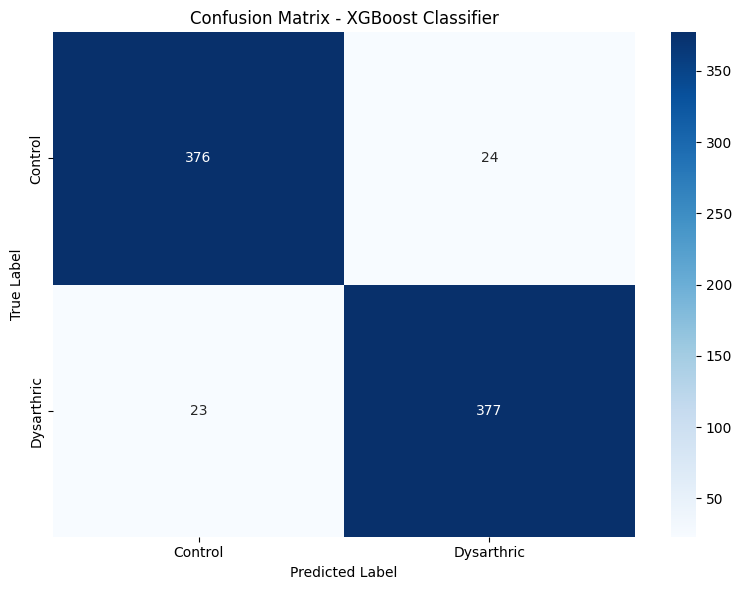


CatBoost Classifier Results:
              precision    recall  f1-score   support

     Control       0.94      0.95      0.95       400
  Dysarthric       0.95      0.94      0.94       400

    accuracy                           0.94       800
   macro avg       0.95      0.95      0.94       800
weighted avg       0.95      0.94      0.94       800



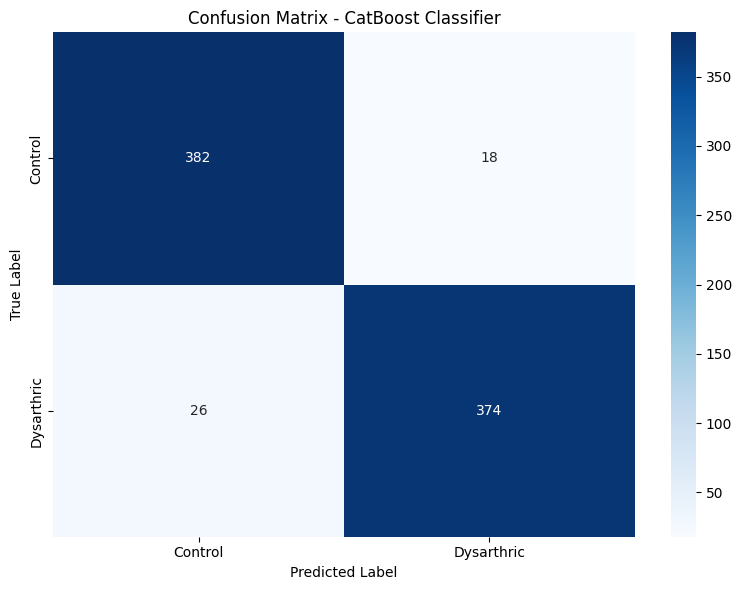


Ensemble Classifier Results:
              precision    recall  f1-score   support

     Control       0.94      0.95      0.95       400
  Dysarthric       0.95      0.94      0.94       400

    accuracy                           0.94       800
   macro avg       0.95      0.95      0.94       800
weighted avg       0.95      0.94      0.94       800



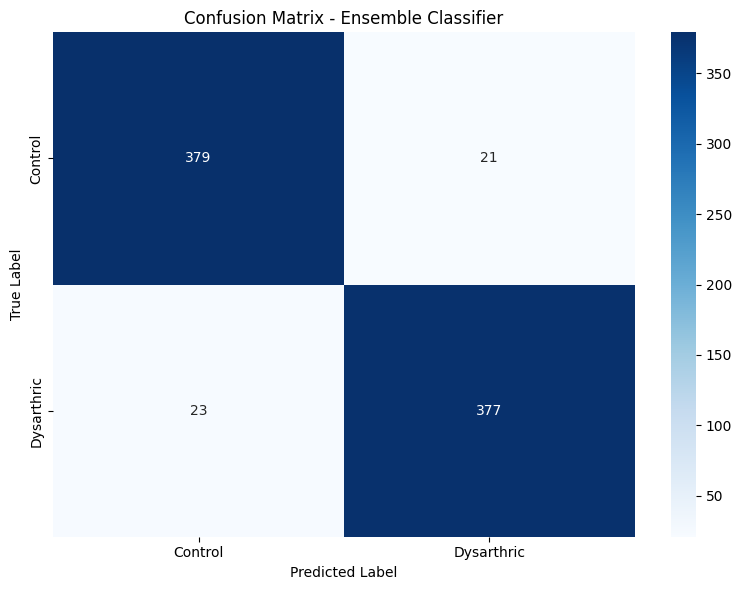

In [16]:
    for name, result in results.items():
        print(f"\n{name} Classifier Results:")
        print(result['classification_report'])
        
        # Plot Confusion Matrix
        plot_confusion_matrix(
            result['confusion_matrix'], 
            ['Control', 'Dysarthric'], 
            f'Confusion Matrix - {name} Classifier'
        )